### Simple illustration on a synthetic dataset

In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from TSVis.synthetic_data import generateSyntheticData

In [12]:
# Generate some synthetic data

data = generateSyntheticData(100,200)
normal = data[0]
decreasing = data[1] / np.max(data[1]) * 30
increasing = data[2]  /np.max(data[2]) * 30
downward = data[3]/np.max(data[3]) * 30
cyclic = data[4]/np.max(data[4]) * 30
upward = data[5]/np.max(data[5]) * 30
t_1 = np.concatenate((cyclic,downward,increasing,normal,decreasing,upward))
t_1.shape

(600, 200)

In [25]:
from TiVy import *
tivy = TiVy(chunk_size = 50,strength=1, use_LSH=True, nPerm=20, bandWidth=0.5)
tivy.cluster_subsequences(t_1)

In [26]:
scan_profile = tivy.prefix_scan(tivy.clusters,tivy.ts_start,minlen=1)

In [27]:
counter = scan_profile['counter']
sequenceClusterDB = scan_profile['sequenceClusterDB']
clusters = tivy.optimize_patterns(sequenceClusterDB,counter,minSupport=10,minLength=50,minSize=1)


In [28]:
result = tivy.output_result(clusters)

In [29]:
# create buffers for visualization
from TSVis.widget import TimeSeriesVis
summary = TimeSeriesVis(n_cols=7,padding=50,n_ticks=3,chart_width=260,chart_height=140,interpolate=500)
summary.fit(result['result'])

Preparing Buffer...


  0%|          | 0/14 [00:00<?, ?it/s]

Box(children=(Label(value='Show Lines'), Checkbox(value=False, description='|', indent=False, layout=Layout(wi…

RFBOutputContext()

CanvasBackend(css_height='380px', css_width='2170px')
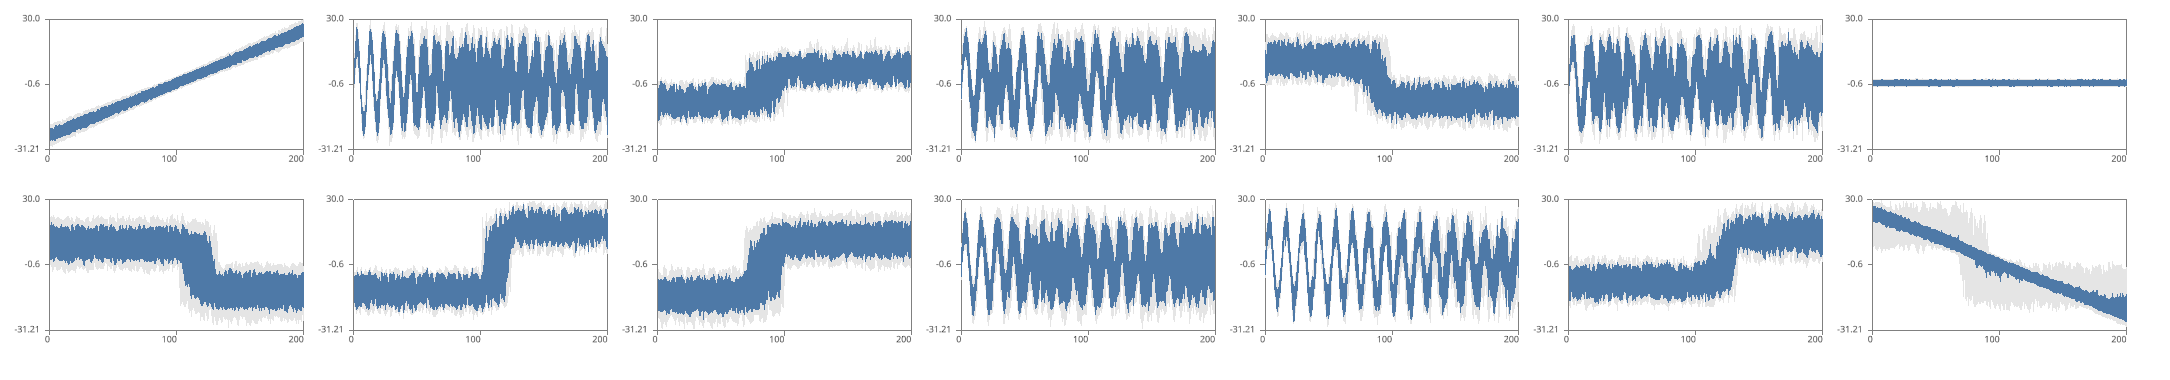

In [30]:
# render the result
summary.visualize()